In [1]:
'''Develop a scalable, production-grade RESTful API using frameworks like FastAPI or
 Flask to serve machine learning models with optimized inference response times and robust error handling.'''

'Develop a scalable, production-grade RESTful API using frameworks like FastAPI or\n Flask to serve machine learning models with optimized inference response times and robust error handling.'

In [2]:
# import api frameworks and modeling libraries
import os
import sys
import time
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, r2_score
from flask import Flask, request, jsonify

In [3]:
# load dataset and inspect pharmacy transactions
file_name = 'global_pharmacy_sales_data.csv' if os.path.exists('global_pharmacy_sales_data.csv') else 'global_pharmacy_salles_data.csv'
df = pd.read_csv(file_name)
print('dataset shape:', df.shape)
df.head()

dataset shape: (177990, 14)


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [4]:
# build and train production sales prediction pipeline
feature_names = ['unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
X = df[feature_names].values
y = df['units_sold'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

production_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', GradientBoostingRegressor(n_estimators=35, max_depth=5, random_state=42))
])

production_pipeline.fit(X_train[:25000], y_train[:25000])
test_r2 = r2_score(y_test, production_pipeline.predict(X_test))
print(f'production pipeline trained: test r2={test_r2:.4f}')

production pipeline trained: test r2=0.9252


In [5]:
# serialize model artifact and schema metadata
artifact_path = 'pharmacy_sales_api_artifact.joblib'
artifact_metadata = {
    'pipeline': production_pipeline,
    'expected_features': feature_names,
    'version': '1.0.0',
    'created_at': time.strftime('%Y-%m-%d %H:%M:%S'),
    'feature_ranges': {
        'unit_price': {'min': float(df['unit_price'].min()), 'max': float(df['unit_price'].max())},
        'stock_level': {'min': float(df['stock_level'].min()), 'max': float(df['stock_level'].max())},
        'expiry_days_remaining': {'min': float(df['expiry_days_remaining'].min()), 'max': float(df['expiry_days_remaining'].max())},
        'covid_flag': {'allowed': [0, 1]}
    }
}

joblib.dump(artifact_metadata, artifact_path)
print(f'artifact saved: {artifact_path} ({os.path.getsize(artifact_path) / 1024:.2f} kb)')

artifact saved: pharmacy_sales_api_artifact.joblib (173.38 kb)


In [6]:
# create restful api app and register health and info endpoints
app = Flask('pharmacy_inference_api')
service_start_time = time.time()

loaded_artifact = joblib.load(artifact_path)
model_pipeline = loaded_artifact['pipeline']
required_features = loaded_artifact['expected_features']
model_version = loaded_artifact['version']

@app.route('/health', methods=['GET'])
def health():
    uptime = time.time() - service_start_time
    return jsonify({
        'status': 'healthy',
        'service': 'pharmacy_sales_inference_api',
        'uptime_seconds': round(uptime, 2),
        'model_version': model_version
    }), 200

@app.route('/info', methods=['GET'])
def info():
    return jsonify({
        'service': 'pharmacy_sales_inference_api',
        'version': model_version,
        'features': required_features,
        'feature_ranges': loaded_artifact['feature_ranges']
    }), 200

In [7]:
# implement single prediction endpoint with input validation and error handling
@app.route('/predict', methods=['POST'])
def predict():
    start_ts = time.perf_counter()
    data = request.get_json(silent=True)
    
    if not data or not isinstance(data, dict):
        return jsonify({'error': 'bad request: json body required'}), 400
    
    missing_fields = [f for f in required_features if f not in data]
    if missing_fields:
        return jsonify({'error': f'bad request: missing required fields {missing_fields}'}), 400
    
    try:
        row_values = []
        for f in required_features:
            val = float(data[f])
            if np.isnan(val):
                return jsonify({'error': f'bad request: field {f} cannot be nan'}), 400
            row_values.append(val)
    except (ValueError, TypeError):
        return jsonify({'error': 'bad request: all feature values must be numeric'}), 400
    
    if data['unit_price'] < 0 or data['stock_level'] < 0:
        return jsonify({'error': 'bad request: unit_price and stock_level must be non-negative'}), 400
    
    input_arr = np.array(row_values).reshape(1, -1)
    predicted_val = float(model_pipeline.predict(input_arr)[0])
    response_latency_ms = (time.perf_counter() - start_ts) * 1000
    
    return jsonify({
        'prediction': round(predicted_val, 2),
        'latency_ms': round(response_latency_ms, 3),
        'status': 'success'
    }), 200

In [8]:
# implement batch prediction endpoint for high throughput
@app.route('/predict_batch', methods=['POST'])
def predict_batch():
    start_ts = time.perf_counter()
    data = request.get_json(silent=True)
    
    if not data or 'records' not in data or not isinstance(data['records'], list):
        return jsonify({'error': 'bad request: payload must contain records list'}), 400
    
    records = data['records']
    if len(records) == 0:
        return jsonify({'error': 'bad request: records list cannot be empty'}), 400
    
    matrix = []
    for idx, rec in enumerate(records):
        try:
            row = [float(rec[f]) for f in required_features]
            matrix.append(row)
        except (KeyError, ValueError, TypeError) as exc:
            return jsonify({'error': f'bad request at record index {idx}: {str(exc)}'}), 400
    
    preds = model_pipeline.predict(np.array(matrix)).tolist()
    total_latency_ms = (time.perf_counter() - start_ts) * 1000
    
    return jsonify({
        'predictions': [round(p, 2) for p in preds],
        'batch_size': len(preds),
        'total_latency_ms': round(total_latency_ms, 3),
        'avg_latency_per_sample_ms': round(total_latency_ms / len(preds), 4),
        'status': 'success'
    }), 200

In [9]:
# test health check and info endpoints with test client
client = app.test_client()

res_health = client.get('/health')
print('health response status:', res_health.status_code)
print('health response payload:', res_health.get_json())

res_info = client.get('/info')
print('\ninfo response status:', res_info.status_code)
print('info response payload:', res_info.get_json())

health response status: 200
health response payload: {'model_version': '1.0.0', 'service': 'pharmacy_sales_inference_api', 'status': 'healthy', 'uptime_seconds': 0.08}

info response status: 200
info response payload: {'feature_ranges': {'covid_flag': {'allowed': [0, 1]}, 'expiry_days_remaining': {'max': 720.0, 'min': 30.0}, 'stock_level': {'max': 5124.0, 'min': 0.0}, 'unit_price': {'max': 100.0, 'min': 5.0}}, 'features': ['unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag'], 'service': 'pharmacy_sales_inference_api', 'version': '1.0.0'}


In [10]:
# test single and batch predictions with valid payloads
valid_record = {
    'unit_price': 18.50,
    'stock_level': 2400,
    'expiry_days_remaining': 420,
    'covid_flag': 0
}

res_single = client.post('/predict', json=valid_record)
print('single prediction status:', res_single.status_code)
print('single prediction body:', res_single.get_json())

batch_records = {'records': [valid_record, valid_record, valid_record]}
res_batch = client.post('/predict_batch', json=batch_records)
print('\nbatch prediction status:', res_batch.status_code)
print('batch prediction body:', res_batch.get_json())

single prediction status: 200
single prediction body: {'latency_ms': 1.535, 'prediction': 2521.84, 'status': 'success'}

batch prediction status: 200
batch prediction body: {'avg_latency_per_sample_ms': 0.5901, 'batch_size': 3, 'predictions': [2521.84, 2521.84, 2521.84], 'status': 'success', 'total_latency_ms': 1.77}


In [11]:
# test robust error handling with edge cases and malformed requests
test_cases = [
    ('empty body', {}),
    ('missing field', {'unit_price': 20.0}),
    ('invalid data type', {'unit_price': 'invalid', 'stock_level': 100, 'expiry_days_remaining': 200, 'covid_flag': 0}),
    ('negative value', {'unit_price': -5.0, 'stock_level': 100, 'expiry_days_remaining': 200, 'covid_flag': 0})
]

for desc, payload in test_cases:
    err_res = client.post('/predict', json=payload)
    print(f'{desc} -> status: {err_res.status_code}, error: {err_res.get_json()}')

empty body -> status: 400, error: {'error': 'bad request: json body required'}
missing field -> status: 400, error: {'error': "bad request: missing required fields ['stock_level', 'expiry_days_remaining', 'covid_flag']"}
invalid data type -> status: 400, error: {'error': 'bad request: all feature values must be numeric'}
negative value -> status: 400, error: {'error': 'bad request: unit_price and stock_level must be non-negative'}


In [12]:
# benchmark api response times across repeated requests
response_times_ms = []

for _ in range(100):
    t0 = time.perf_counter()
    r = client.post('/predict', json=valid_record)
    response_times_ms.append((time.perf_counter() - t0) * 1000)

p50 = np.percentile(response_times_ms, 50)
p90 = np.percentile(response_times_ms, 90)
p95 = np.percentile(response_times_ms, 95)
p99 = np.percentile(response_times_ms, 99)

print(f'api p50 latency: {p50:.3f} ms')
print(f'api p90 latency: {p90:.3f} ms')
print(f'api p95 latency: {p95:.3f} ms')
print(f'api p99 latency: {p99:.3f} ms')

api p50 latency: 1.329 ms
api p90 latency: 1.870 ms
api p95 latency: 2.113 ms
api p99 latency: 2.478 ms


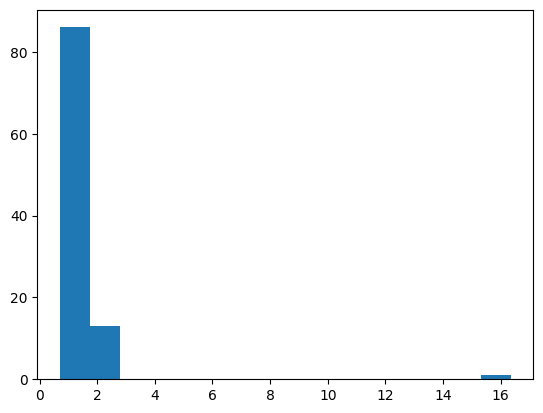

In [13]:
# plot api inference response time distribution
plt.hist(response_times_ms, bins=15)
plt.show()